# code_078 · Bayesian estimation and hierarchical models

**Book:** section 16.2. A self-contained probabilistic response-model laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_16_GUIDE.md), [run evidence](../CHAPTER_16_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_078).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter();SEED=1678;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 1678


<a id="hierarchy"></a>
## Share information through explicit hyperparameters

A fixed teaching fixture contains eight buildings with inspection counts[4,8,12,20,40,80,160,320] and failure counts[0,1,3,1,5,9,10,30]. These are declared illustrative observations, not field records. Hierarchy: p_g|m,k~Beta(m*k,(1-m)*k), failures_g|p_g~Binomial(n_g,p_g). Hyperpriors: m~Beta(2,8) truncated to[.01,.6]; v=log(k)~Normal(log20,.8) truncated to[0,log100]. A61x61 trapezoid quadrature in(m,v) integrates the joint posterior, including hyperparameter uncertainty; it is a finite numerical approximation, not an empirical-Bayes plug-in. All conditional group posteriors are Beta. Prior predictive sampling uses only the stated hyperprior; no prior is revised after its displayed check.


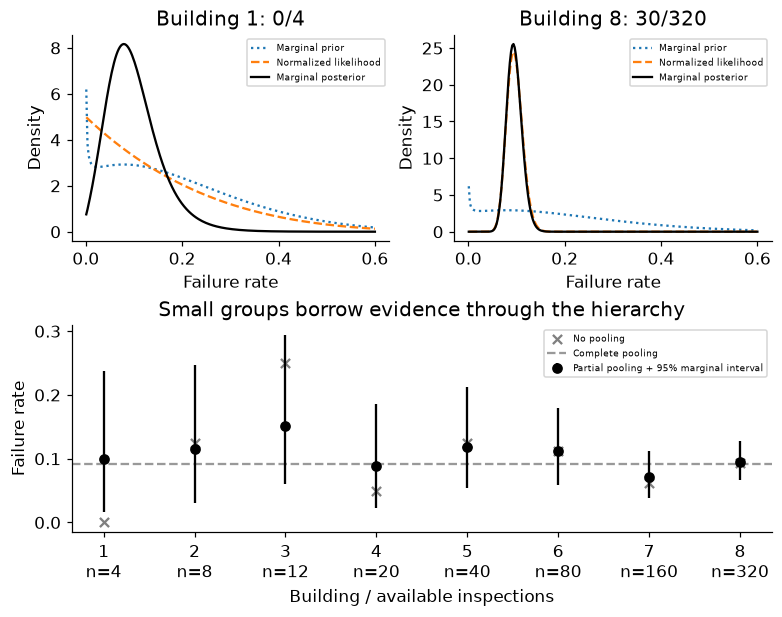

In [2]:
from scipy.special import betaln,logsumexp,expit,logit
from scipy.stats import beta as beta_distribution,norm
n=np.array([4,8,12,20,40,80,160,320]);s=np.array([0,1,3,1,5,9,10,30]);m_grid=np.linspace(.01,.6,61);v_grid=np.linspace(0,np.log(100),61);M,V=np.meshgrid(m_grid,v_grid,indexing='ij');K=np.exp(V);a=M*K;b=(1-M)*K
trap=np.ones(61);trap[[0,-1]]=.5;log_cells=np.log(trap[:,None]*trap[None,:]);log_prior_density=beta_distribution.logpdf(M,2,8)+norm.logpdf(V,np.log(20),.8)
log_likelihood=np.sum(betaln(a[:,:,None]+s,b[:,:,None]+n-s)-betaln(a,b)[:,:,None],axis=2);prior_logmass=log_prior_density+log_cells;prior_mass=np.exp(prior_logmass-logsumexp(prior_logmass));posterior_logmass=prior_logmass+log_likelihood;posterior_mass=np.exp(posterior_logmass-logsumexp(posterior_logmass))
assert np.isclose(prior_mass.sum(),1) and np.isclose(posterior_mass.sum(),1);assert np.all((s>=0)&(s<=n))
conditional_mean=(s[None,None,:]+a[:,:,None])/(n[None,None,:]+K[:,:,None]);group_mean=np.sum(posterior_mass[:,:,None]*conditional_mean,axis=(0,1))
# A denser independent quadrature checks the reported group means.
fm,fv=np.meshgrid(np.linspace(.01,.6,121),np.linspace(0,np.log(100),121),indexing='ij');fk=np.exp(fv);fa=fm*fk;fb=(1-fm)*fk;ft=np.ones(121);ft[[0,-1]]=.5
fl=beta_distribution.logpdf(fm,2,8)+norm.logpdf(fv,np.log(20),.8)+np.log(ft[:,None]*ft[None,:])+np.sum(betaln(fa[:,:,None]+s,fb[:,:,None]+n-s)-betaln(fa,fb)[:,:,None],axis=2);fw=np.exp(fl-logsumexp(fl));fine_mean=np.sum(fw[:,:,None]*(s[None,None,:]+fa[:,:,None])/(n[None,None,:]+fk[:,:,None]),axis=(0,1));refinement_error=float(np.max(np.abs(fine_mean-group_mean)));assert refinement_error<.001
RESULTS['grid_refinement']={'coarse_points_per_axis':61,'fine_points_per_axis':121,'max_group_posterior_mean_difference':refinement_error,'posterior_continuous_integration_exact':False}

def draw_groups(mass,draws):
 ids=rng.choice(mass.size,draws,p=mass.ravel());aa=a.ravel()[ids,None];bb=b.ravel()[ids,None];return ids,rng.beta(aa+s,bb+n-s)

# Prior predictive simulation uses prior hyperparameters and no observed counts.
prior_ids=rng.choice(prior_mass.size,5000,p=prior_mass.ravel());prior_p=rng.beta(a.ravel()[prior_ids,None],b.ravel()[prior_ids,None],size=(5000,8));prior_counts=rng.binomial(n[None,:],prior_p)
ids,p_draw=draw_groups(posterior_mass,5000);lo,hi=np.quantile(p_draw,[.025,.975],axis=0);raw=s/n;pooled=float(s.sum()/n.sum());np.testing.assert_allclose(np.sum(posterior_mass[:,:,None]*(s[None,None,:]+a[:,:,None])/(n[None,None,:]+K[:,:,None]),axis=(0,1)),group_mean)
RESULTS['posterior']={'inspection_counts':n.tolist(),'failure_counts':s.tolist(),'raw_rates':raw.tolist(),'complete_pooling_rate':pooled,'partial_pooling_means':group_mean.tolist(),'mixture_credible_95_lower':lo.tolist(),'mixture_credible_95_upper':hi.tolist(),'posterior_hyper_mean_m':float(np.sum(posterior_mass*M)),'posterior_hyper_mean_k':float(np.sum(posterior_mass*K)),'quadrature_grid':[61,61],'truncated_hyperprior_ranges':{'m':[.01,.6],'log_k':[0,float(np.log(100))]},'group_draws':5000};RESULTS['prior_predictive']={'draws':5000,'group_expected_rate':float(np.sum(prior_mass*M)),'mean_total_failures':float(prior_counts.sum(axis=1).mean()),'probability_any_group_rate_above_half':float(np.mean(np.any(prior_counts/n[None,:]>.5,axis=1)))}
fig=plt.figure(figsize=(7,5.5));gs=fig.add_gridspec(2,2);density_x=np.linspace(.001,.6,240)
for col,g in enumerate([0,7]):
 ax=fig.add_subplot(gs[0,col]);prior_density=np.sum(prior_mass[:,:,None]*beta_distribution.pdf(density_x[None,None,:],a[:,:,None],b[:,:,None]),axis=(0,1));post_density=np.sum(posterior_mass[:,:,None]*beta_distribution.pdf(density_x[None,None,:],a[:,:,None]+s[g],b[:,:,None]+n[g]-s[g]),axis=(0,1));likelihood_shape=beta_distribution.pdf(density_x,s[g]+1,n[g]-s[g]+1);ax.plot(density_x,prior_density,':',label='Marginal prior');ax.plot(density_x,likelihood_shape,'--',label='Normalized likelihood');ax.plot(density_x,post_density,'-',color='black',label='Marginal posterior');ax.set(xlabel='Failure rate',ylabel='Density',title=f'Building {g+1}: {s[g]}/{n[g]}');ax.legend(fontsize=6)
ax=fig.add_subplot(gs[1,:]);x=np.arange(8);ax.scatter(x,raw,marker='x',color='.5',label='No pooling');ax.axhline(pooled,color='.6',ls='--',label='Complete pooling');ax.errorbar(x,group_mean,yerr=np.vstack([group_mean-lo,hi-group_mean]),fmt='o',color='black',label='Partial pooling + 95% marginal interval');ax.set(xticks=x,xticklabels=[f'{i+1}\nn={v}' for i,v in enumerate(n)],ylabel='Failure rate',xlabel='Building / available inspections',title='Small groups borrow evidence through the hierarchy');ax.legend(fontsize=6);plt.show()


<a id="prediction"></a>
## Prediction integrates rate uncertainty and future sampling

For twenty future inspections per building, each posterior draw first samples its group rate, then a Binomial count. Compare with a separate illustrative future realization generated from declared oracle rates[.02,.08,.18,.06,.12,.09,.07,.1]. Those oracle rates and future counts are never inference inputs. The intervals condition on exchangeability, the truncated hyperpriors and the observation model; eight displayed future counts do not establish population coverage. Group credible intervals are intervals for latent rates, while these future-count intervals include another sampling layer.


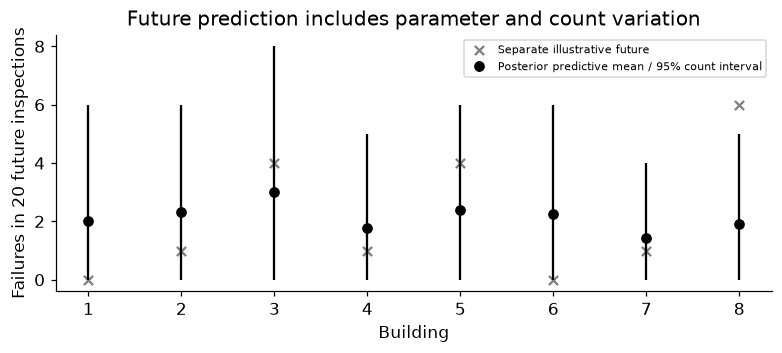

In [3]:
future_n=20;future_draw=rng.binomial(future_n,p_draw);future_interval=np.quantile(future_draw,[.025,.975],axis=0);oracle=np.array([.02,.08,.18,.06,.12,.09,.07,.1]);future_observed=rng.binomial(future_n,oracle);assert future_draw.shape==(5000,8) and np.all((future_draw>=0)&(future_draw<=20));assert np.all((group_mean>0)&(group_mean<1))
RESULTS['future_prediction']={'inspections_per_building':20,'predictive_mean':(future_n*group_mean).tolist(),'predictive_lower':future_interval[0].tolist(),'predictive_upper':future_interval[1].tolist(),'separate_oracle_rates':oracle.tolist(),'separate_future_counts':future_observed.tolist(),'future_data_used_in_fit':False}
fig,ax=plt.subplots(figsize=(7,3.1));mean=future_n*group_mean;ax.errorbar(np.arange(8),mean,yerr=np.vstack([mean-future_interval[0],future_interval[1]-mean]),fmt='o',color='black',label='Posterior predictive mean / 95% count interval');ax.scatter(np.arange(8),future_observed,marker='x',color='.5',label='Separate illustrative future');ax.set(xticks=range(8),xticklabels=range(1,9),xlabel='Building',ylabel='Failures in 20 future inspections',title='Future prediction includes parameter and count variation');ax.legend(fontsize=7);plt.show()


In [4]:
summary={'example_id':'code_078','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['prior likelihood posterior and prediction', 'full hyperparameter grid integration', 'unequal group partial pooling', 'prior predictive versus future evidence'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["prior likelihood posterior and prediction", "full hyperparameter grid integration", "unequal group partial pooling", "prior predictive versus future evidence"], "elapsed_seconds": 0.314, "example_id": "code_078", "hardware": "Darwin arm64 CPU", "results": {"future_prediction": {"future_data_used_in_fit": false, "inspections_per_building": 20, "predictive_lower": [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0], "predictive_mean": [2.0026308317424646, 2.3141830760360644, 3.0189958752546557, 1.7720705421965988, 2.377689685019615, 2.241350654611228, 1.431535947954803, 1.910274279037213], "predictive_upper": [6.0, 6.0, 8.0, 5.0, 6.0, 6.0, 4.0, 5.0], "separate_future_counts": [0, 1, 4, 1, 4, 0, 1, 6], "separate_oracle_rates": [0.02, 0.08, 0.18, 0.06, 0.12, 0.09, 0.07, 0.1]}, "grid_refinement": {"coarse_points_per_axis": 61, "fine_points_per_axis": 121, "max_group_posterior_mean_difference": 3.962686708908203e-06, "posterior_continuous_integration_e